In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!git clone https://github.com/sunidhishekar-create/tensorix-kd-slm.git
%cd tensorix-kd-slm
!mkdir -p /content/data
!cp /content/drive/MyDrive/tensorix/data/* /content/data/
!nvidia-smi | head -n 12

Cloning into 'tensorix-kd-slm'...
remote: Enumerating objects: 37, done.
remote: Counting objects: 100% (37/37), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 37 (delta 12), reused 16 (delta 2), pack-reused 0 (from 0)
Receiving objects: 100% (37/37), 24.13 KiB | 12.07 MiB/s, done.
Resolving deltas: 100% (12/12), done.
/content/tensorix-kd-slm
Sat Oct 24 11:26:05 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+=====

In [4]:
!ls -lh /content/data

total 914M
-rw------- 1 root root 905M Oct 24 11:26 train.bin
-rw------- 1 root root 9.1M Oct 24 11:26 val.bin
-rw------- 1 root root 149K Oct 24 11:26 vocab.json


In [5]:
!python src/train.py --data_dir /content/data --out_dir /content/speedtest --max_steps 100 --eval_interval 100 --eval_iters 10 --save_interval 100

device=cuda params=19.4M vocab=22875 tokens/step=16384
step 50 | loss 6.014 | lr 2.50e-04 | 322 ms/step
step 100 | loss 3.937 | lr 5.00e-04 | 301 ms/step
>>> step 100 | train 3.928 | val 3.932 | val ppl 51.00
done


In [7]:
!python src/train.py --data_dir /content/data --out_dir /content/drive/MyDrive/tensorix/checkpoints/baseline --max_steps 20000 --eval_interval 1000 --save_interval 1000

resumed from step 20000
device=cuda params=19.4M vocab=22875 tokens/step=16384
done


In [8]:
import pandas as pd
df = pd.read_csv('/content/drive/MyDrive/tensorix/checkpoints/baseline/log.csv')
print(df.tail(5).to_string(index=False))
print("\nbest val ppl:", df['val_ppl'].min(), "at step", int(df.loc[df['val_ppl'].idxmin(), 'step']))
import os
print(os.listdir('/content/drive/MyDrive/tensorix/checkpoints/baseline'))

 step  train_loss  val_loss  val_ppl       lr
16000    1.524827  1.544389 4.685110 0.000188
17000    1.520563  1.525088 4.595550 0.000150
18000    1.500258  1.509419 4.524103 0.000122
19000    1.500348  1.507931 4.517377 0.000106
20000    1.500725  1.492692 4.449056 0.000100

best val ppl: 4.449055872863618 at step 20000
['log.csv', 'best.pt', 'ckpt.pt']


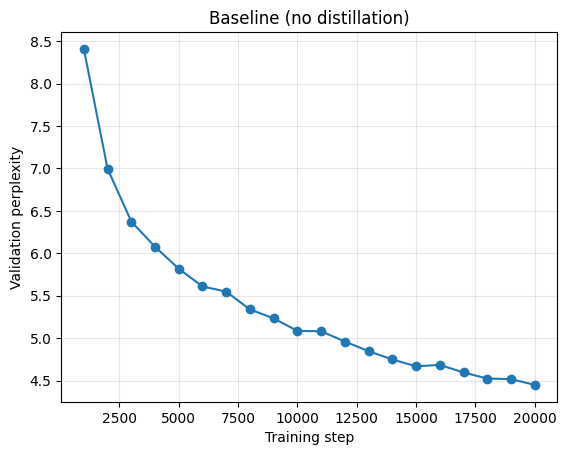

In [9]:
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv('/content/drive/MyDrive/tensorix/checkpoints/baseline/log.csv')
plt.plot(df['step'], df['val_ppl'], marker='o')
plt.xlabel('Training step'); plt.ylabel('Validation perplexity'); plt.title('Baseline (no distillation)')
plt.grid(alpha=0.3)
plt.savefig('/content/drive/MyDrive/tensorix/results/baseline_val_ppl.png', dpi=150, bbox_inches='tight')
plt.show()